# CAMP2Ex RF17 RSP Data

A quick look at the data from the RSP aboard the ER2. There are polarimetric retrievals of Reff and Veff between 2-4:30. The RSP Re seems to agree well with the in-situ.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

PROJECT_ROOT = Path().resolve().parent.parent.parent
sys.path.append(str(PROJECT_ROOT))


In [2]:
import src.CAMP2Ex as cx
plt.style.use('seaborn-v0_8-paper')

In [3]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
rsp_file = RAW_DATA / 'CAMP2Ex_RSP' / 'CAMP2EX-RSP1-CLD_P3B_20191001_R1.ict'
INTERIM_DATA = PROJECT_ROOT / 'data' / 'interim'

# Load MISR OBS
obs_file = INTERIM_DATA / 'MISR_OBS_CAMP2Ex_RF17_wide.nc'
obs = xr.load_dataset(obs_file, engine='netcdf4')

In [4]:
rsp = pd.read_csv(rsp_file, skiprows=48, header=0)
rsp['Day_Of_Year'] = 274
rsp['Time_Start'] = rsp[' Time_mid']
rsp = cx.make_datetime(rsp, year_default=2019)

<Axes: xlabel='datetime', ylabel=' CTH'>

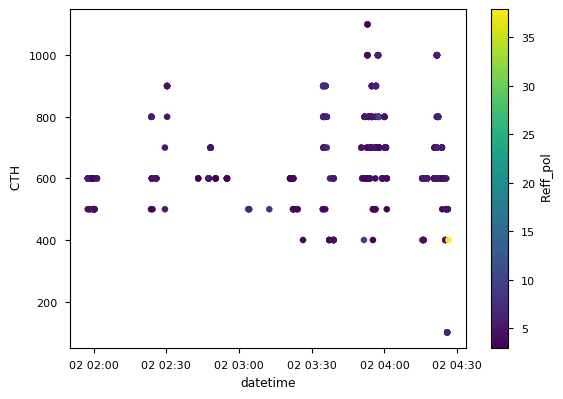

In [5]:
rsp_subset = rsp[
    (rsp[' Reff_pol'] > 0) 
    # & (rsp[' Reff_pol'] < 35) 
    & (rsp[' CTH'] < 1500)
]
rsp_subset.plot.scatter(x='datetime', y=' CTH', c=' Reff_pol')

<Axes: xlabel='datetime', ylabel=' Time_mid'>

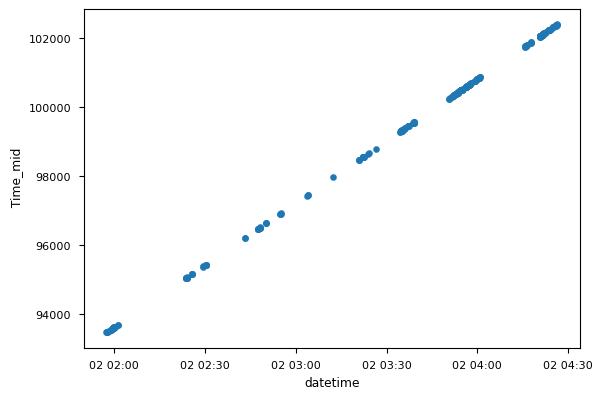

In [6]:
rsp_subset.plot.scatter(x='datetime', y=' Time_mid')

Text(0, 0.5, 'Latitude')

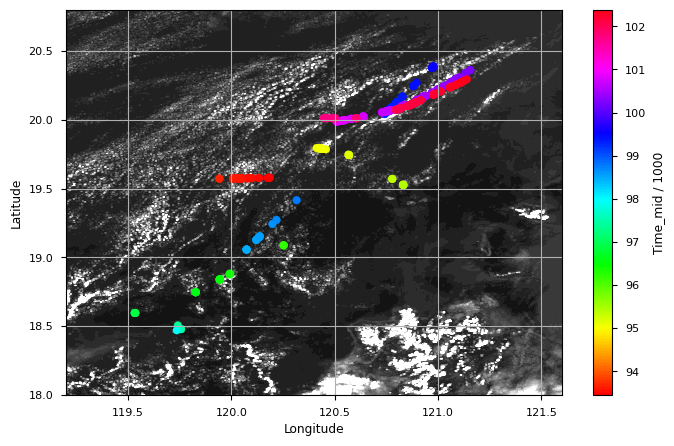

In [7]:
# lon_window = [118, 123]
# lat_window = [17.4, 21.5]
lon_window = [119.2, 121.6]
lat_window = [18.0, 20.8]
# lon_window = [119.7, 121.0]
# lat_window = [18.5, 20.2]

f, ax = plt.subplots(1, 1, figsize=(8,5))
brf_ax = ax.contourf(obs.lon275.data, obs.lat275.data, obs.brf.isel(camera=4).data, vmin=0, vmax=0.30, cmap='gray', levels=100)
# ax.scatter(rsp_subset[' Lon'], rsp_subset[' Lat'], c='tab:orange', marker='x')
s = ax.scatter(rsp_subset[' Lon'], rsp_subset[' Lat'], c=rsp_subset[' Time_mid']/1000, cmap='hsv')
plt.colorbar(s, ax=ax, label='Time_mid / 1000')

# Adjust window
ax.set_xlim(lon_window)
ax.set_ylim(lat_window)
ax.grid()
# ax.legend(loc='upper left')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

In [8]:
RAW_DATA = PROJECT_ROOT / 'data' / 'raw'
nav_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'CAMP2EX-MetNav_P3B_20191001_R0.ict'
fcdp_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-FCDP_P3B_20191001_R1.ict'
tds_file = RAW_DATA / 'CAMP2Ex_SPEC' / 'PaulLawson' / 'CAMP2Ex-2DS10_P3B_20191001_R0.ict'
p3 = cx.load_FCDP_2DS(fcdp_file, tds_file, nav_file, breakpoint=40, resample='2s')

start_time = pd.to_datetime('2019-10-02 00:00:00')
end_time = pd.to_datetime('2019-10-02 02:00:00')
# start_time = pd.to_datetime('2019-10-02 01:45:25')
# end_time = pd.to_datetime('2019-10-02 01:46:10')

p3_subset = p3[
    # (p3['N_L'] > 10000)
    (p3['ext_km'] > 0.3)
    & (p3.index > start_time)
    & (p3.index < end_time)
    & (p3['GPS_Altitude'] < 1250)
]

/data/gdi/b/johntl3/LundstromPub2025/src/CAMP2Ex.py:110: RuntimeWarning: invalid value encountered in divide
  Re = np.sum(n * r**3, axis=-1) / np.sum(n * r**2, axis=-1)


Re = 3.938 [um/km] * z + 2.895 [um]


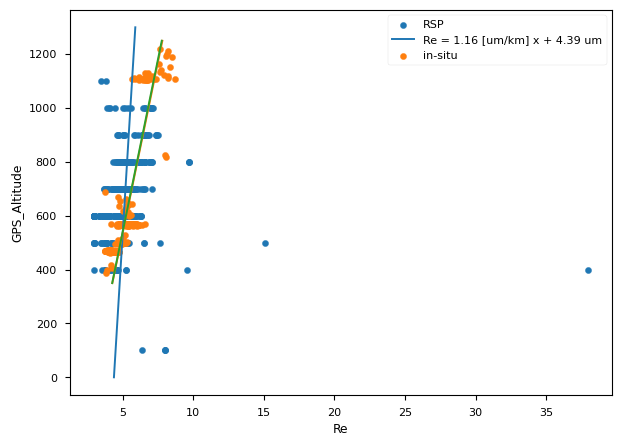

In [9]:
m_re, b_re = cx.VertLinearRegression(rsp_subset, x_var=' CTH', y_var=' Reff_pol')
f, ax = plt.subplots(1, 1, figsize=(7,5))
rsp_subset.plot.scatter(x=' Reff_pol', y=' CTH', c='tab:blue', ax=ax, label='RSP')
x = np.linspace(0, 1300, 100)
y = m_re*x + b_re
ax.plot(y, x, label=f'Re = {m_re*1000:.2f} [um/km] x + {b_re:.2f} um')
ax.legend()

slope, intercept = cx.VertLinearRegression(p3_subset, x_var='GPS_Altitude', y_var='Re')
p3_subset.plot.scatter(x='Re', y='GPS_Altitude', c='tab:orange', ax=ax, label='in-situ')
x = np.array([350, 1250])
y = slope * x + intercept
ax.plot(y, x)
ax.plot(3.9*1e-3*x+2.9, x)
print(f'Re = {slope*1e3:.3f} [um/km] * z + {intercept:.3f} [um]')


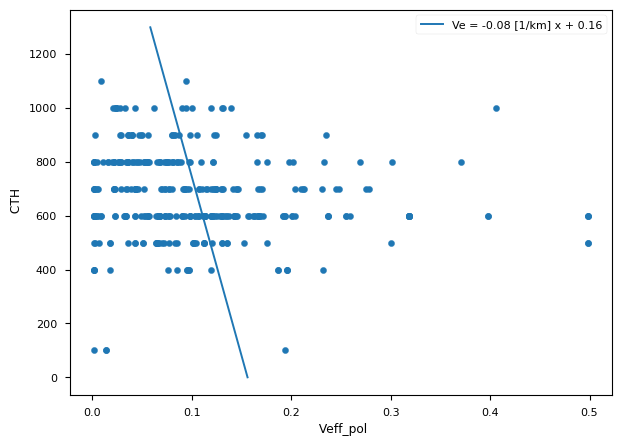

In [10]:
m_ve, b_ve = cx.VertLinearRegression(rsp_subset, x_var=' CTH', y_var=' Veff_pol')
f, ax = plt.subplots(1, 1, figsize=(7,5))
rsp_subset.plot.scatter(x=' Veff_pol', y=' CTH', ax=ax)
x = np.linspace(0, 1300, 100)
y = m_ve*x + b_ve
ax.plot(y, x, label=f'Ve = {m_ve*1000:.2f} [1/km] x + {b_ve:.2f}')
ax.legend()